# Histogram of oriented gradients

This notebook builds a simple HOG descriptor for a grayscale image. It uses Sobel gradients, distributes their magnitudes between neighboring orientation bins, and normalizes overlapping blocks. The static plot works on GitHub without an animation player. This educational implementation does not include every interpolation and normalization step used by production HOG libraries.

**Data:** No dataset. The example reads one local image, `img1.jpg`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import sobel

with Image.open("img1.jpg") as image:
    pixels = np.asarray(image.convert("L").resize((128, 128)), dtype=float)

gx = sobel(pixels, axis=1, mode="reflect")
gy = sobel(pixels, axis=0, mode="reflect")
magnitude = np.hypot(gx, gy)
orientation = np.degrees(np.arctan2(gy, gx)) % 180

In [2]:
cell_size, num_bins = 8, 9
bin_width = 180 / num_bins
cells_y, cells_x = np.array(pixels.shape) // cell_size
cell_hist = np.zeros((cells_y, cells_x, num_bins))

for row in range(cells_y):
    for col in range(cells_x):
        region = np.s_[row * cell_size:(row + 1) * cell_size,
                       col * cell_size:(col + 1) * cell_size]
        positions = orientation[region] / bin_width
        lower = positions.astype(int) % num_bins
        weight = positions - np.floor(positions)
        np.add.at(cell_hist[row, col], lower.ravel(), (magnitude[region] * (1 - weight)).ravel())
        np.add.at(cell_hist[row, col], ((lower + 1) % num_bins).ravel(), (magnitude[region] * weight).ravel())

blocks = []
for row in range(cells_y - 1):
    for col in range(cells_x - 1):
        block = cell_hist[row:row + 2, col:col + 2].ravel()
        blocks.append(block / np.sqrt(np.dot(block, block) + 1e-12))
hog_features = np.concatenate(blocks)
print(f"HOG descriptor length: {hog_features.size}")
assert hog_features.size == 15 * 15 * 2 * 2 * num_bins
assert np.isfinite(hog_features).all()

HOG descriptor length: 8100


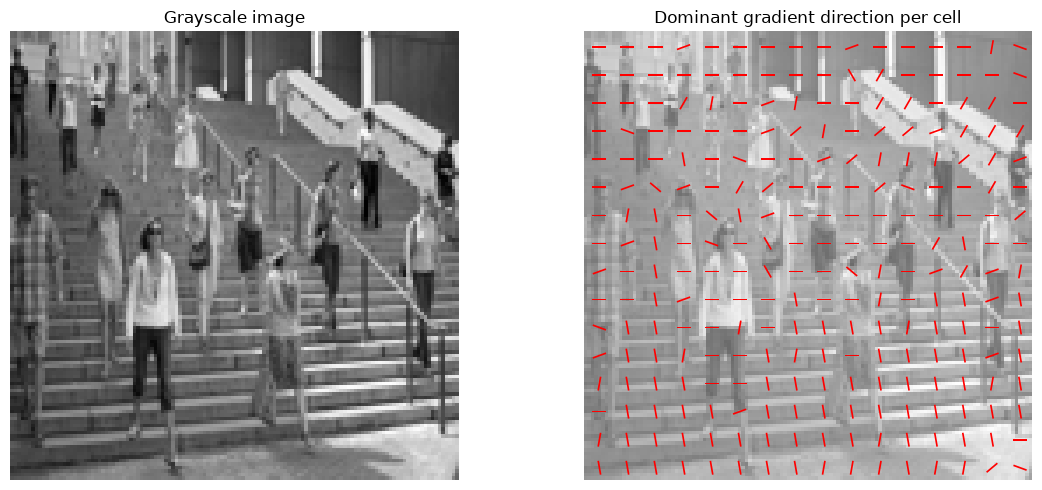

In [3]:
dominant = np.deg2rad(np.argmax(cell_hist, axis=2) * bin_width)
y, x = np.mgrid[:cells_y, :cells_x]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(pixels, cmap="gray")
axes[0].set_title("Grayscale image")
axes[1].imshow(pixels, cmap="gray", alpha=0.6)
axes[1].quiver((x + 0.5) * cell_size, (y + 0.5) * cell_size,
               np.cos(dominant), np.sin(dominant), color="red",
               angles="xy", scale_units="xy", scale=0.25, pivot="middle", headlength=0, headaxislength=0)
axes[1].set_title("Dominant gradient direction per cell")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

The descriptor contains one normalized histogram for each overlapping 2 × 2 block. The arrows show the strongest orientation in each cell; they do not show the full histogram.